# 11. Mortalidade

Quantas mulheres morrem de câncer de mama no Brasil, essa mortalidade está aumentando, e onde e em que idade ela cresce mais? A fonte é o Sistema de Informações sobre Mortalidade (SIM), que reúne todas as declarações de óbito do país. Contamos os óbitos de mulheres cuja causa básica foi câncer de mama (CID C50), de 2013 a 2024.

Este caderno avança em quatro passos, cada um respondendo a uma pergunta mais precisa que o anterior. Primeiro, quantos óbitos há. Segundo, por que o número de óbitos, sozinho, engana. Terceiro, como a mortalidade muda por região. Quarto, como ela muda por idade, separando as mulheres com menos e com mais de 50 anos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from mama import codigos as c, graficos as g
from mama.config import FONTE_SIM
from mama.analises import base, mortalidade as mort

pd.set_option("display.max_columns", 20)
sim = base.carregar("sim")
pop = base.carregar("populacao_uf")

## Passo 1. Quantas mulheres morrem por ano

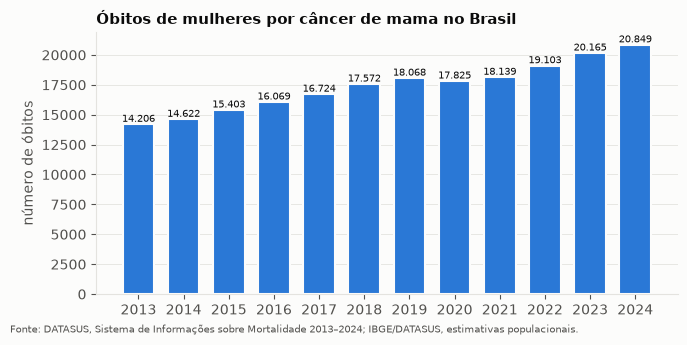

In [2]:
obitos = mort.obitos_por_ano(sim)
base.salvar_tabela(obitos, "11_obitos_por_ano")
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(obitos.ano, obitos.obitos, color=g.AZUL, width=0.7, edgecolor=g.SUPERFICIE, linewidth=1.5)
for x, v in zip(obitos.ano, obitos.obitos):
    ax.text(x, v + 200, f"{v:,.0f}".replace(",", "."), ha="center", fontsize=7.5)
ax.set(title="Óbitos de mulheres por câncer de mama no Brasil", ylabel="número de óbitos")
ax.set_xticks(obitos.ano)
ax.grid(axis="x", visible=False)
g.salvar(fig, "11_obitos_por_ano", FONTE_SIM)
plt.show()

Em 2024, 20.849 mulheres morreram de câncer de mama no Brasil, cerca de 57 por dia. Em 2013 eram 14.206. O valor de 2021, 18.139 óbitos, é idêntico ao publicado pelo INCA, o que confirma que a leitura dos dados está correta.

O aumento de 47% em doze anos parece alarmante, mas esse número sozinho não diz se o risco de morrer de câncer de mama aumentou. O próximo passo explica por quê.

## Passo 2. Por que contar óbitos não basta: taxa bruta e taxa padronizada

O número de óbitos cresce por três motivos que se misturam. A população cresce, então há mais mulheres. A população envelhece, e o câncer de mama é muito mais frequente em mulheres mais velhas. E, por fim, pode haver um aumento real do risco. Para saber se o risco aumentou, é preciso separar esses efeitos.

A taxa bruta resolve o primeiro problema: divide os óbitos pelo número de mulheres e expressa o resultado por 100 mil mulheres. Mas ela ainda cresce quando a população envelhece.

A taxa padronizada por idade resolve o segundo. Ela calcula a taxa de cada faixa de idade separadamente e depois as combina usando sempre a mesma estrutura etária de referência (a população mundial padrão de Segi, a mesma usada pelo INCA). É como perguntar: se a população tivesse sempre a mesma idade, quantas mortes haveria? Assim, uma região com população jovem pode ser comparada com outra de população mais velha, e um ano pode ser comparado com outro.

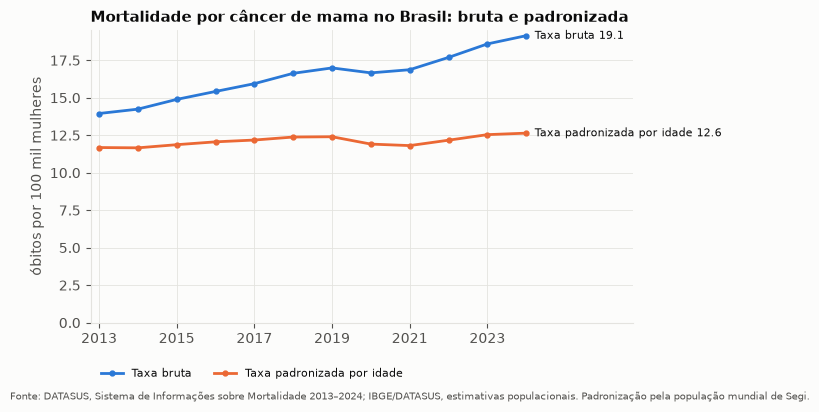

,ano,obitos,taxa_bruta,taxa_padronizada
0,2013,14206.0,13.95,11.68
1,2014,14622.0,14.24,11.66
2,2015,15403.0,14.89,11.87
3,2016,16069.0,15.42,12.06
4,2017,16724.0,15.94,12.18
5,2018,17572.0,16.63,12.38
6,2019,18068.0,16.99,12.4
7,2020,17825.0,16.66,11.91
8,2021,18139.0,16.87,11.81
9,2022,19103.0,17.69,12.17


In [3]:
brasil = mort.taxa_padronizada(sim.assign(pais="Brasil"), pop.assign(pais="Brasil"), por="pais")
base.salvar_tabela(brasil, "11_taxas_brasil")
duas = brasil.melt(id_vars="ano", value_vars=["taxa_bruta", "taxa_padronizada"], var_name="medida", value_name="taxa")
duas["medida"] = duas.medida.map({"taxa_bruta": "Taxa bruta", "taxa_padronizada": "Taxa padronizada por idade"})
fig, ax = g.linhas(duas, "ano", "taxa", "medida", "Mortalidade por câncer de mama no Brasil: bruta e padronizada",
                   "óbitos por 100 mil mulheres", ordem=["Taxa bruta", "Taxa padronizada por idade"])
ax.set_ylim(0, None)
g.salvar(fig, "11_taxa_bruta_x_padronizada", FONTE_SIM + " Padronização pela população mundial de Segi.")
plt.show()
brasil[["ano", "obitos", "taxa_bruta", "taxa_padronizada"]]

A taxa bruta subiu de 14,0 para 19,1 óbitos por 100 mil mulheres. A taxa padronizada subiu bem menos, de 11,7 para 12,6, um aumento de 8%. A diferença entre as duas linhas é o efeito do envelhecimento da população. Em outras palavras, a maior parte do aumento no número de óbitos vem de haver mais mulheres, e mais velhas. Ainda assim, há um aumento real do risco, pequeno no país como um todo, mas que se concentra em regiões e idades específicas, como mostram os próximos passos.

## Passo 3. Mortalidade por região

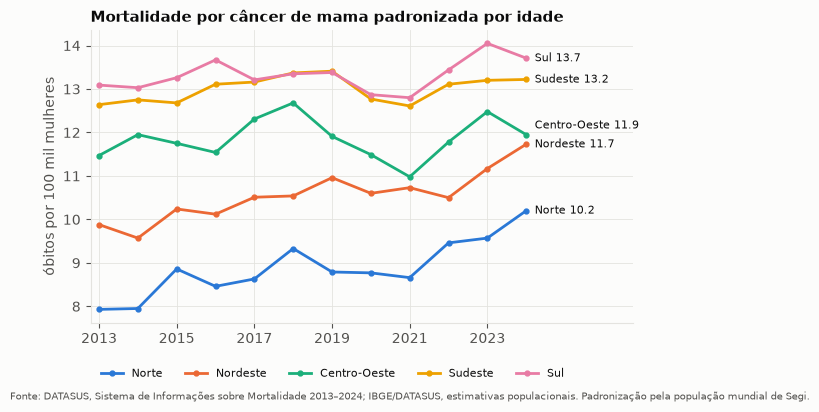

In [4]:
reg = mort.taxa_padronizada(sim, pop)
base.salvar_tabela(reg, "11_taxa_padronizada_regiao")
fig, ax = g.linhas(reg, "ano", "taxa_padronizada", "regiao", "Mortalidade por câncer de mama padronizada por idade",
                   "óbitos por 100 mil mulheres", ordem=c.REGIOES)
g.salvar(fig, "11_taxa_padronizada_regiao", FONTE_SIM + " Padronização pela população mundial de Segi.")
plt.show()

O gráfico mostra duas coisas ao mesmo tempo. Sul e Sudeste têm as maiores taxas, cerca de 13 a 14 óbitos por 100 mil mulheres, e elas estão estáveis. Norte e Nordeste têm as menores taxas, mas são as que mais crescem. O gráfico seguinte mostra essa variação diretamente.

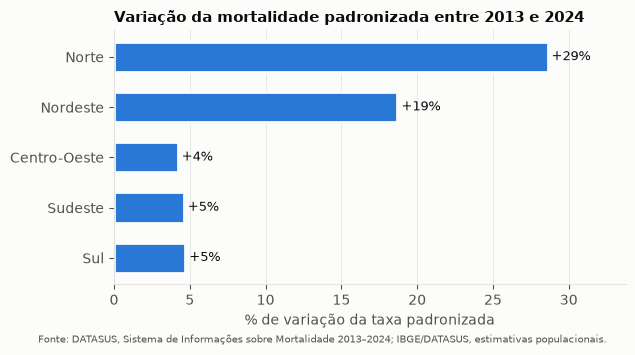

,2013,2024,variacao_pct
regiao,,,
Norte,7.93,10.2,28.6
Nordeste,9.88,11.73,18.7
Centro-Oeste,11.47,11.95,4.2
Sudeste,12.64,13.22,4.6
Sul,13.09,13.71,4.7


In [5]:
var = mort.variacao(reg, "taxa_padronizada", ["regiao"], 2013, 2024).set_index("regiao").reindex(c.REGIOES)
base.salvar_tabela(var, "11_variacao_taxa_padronizada_regiao", index=True)
fig, ax = g.barras_h(var.variacao_pct, "Variação da mortalidade padronizada entre 2013 e 2024",
                     "% de variação da taxa padronizada", fmt="+{:.0f}%")
g.salvar(fig, "11_variacao_mortalidade_regiao", FONTE_SIM)
plt.show()
var

Entre 2013 e 2024, a mortalidade padronizada subiu 29% no Norte e 19% no Nordeste, contra menos de 5% nas outras três regiões. Por que o Sul tem a maior taxa? O câncer de mama é mais frequente onde há mais fatores de risco ligados à urbanização e à vida reprodutiva (menos filhos, primeira gestação mais tarde, menos amamentação), e o Sul e o Sudeste passaram por essas mudanças antes. Por que o Norte cresce mais? Porque essas mudanças chegaram depois, e porque lá o diagnóstico é mais tardio e o acesso ao tratamento mais difícil, como mostram os cadernos 04, 06, 09 e 10. A tendência é que as regiões convirjam, e o risco é que o Norte e o Nordeste passem a ter a mesma incidência do Sul sem ter a mesma estrutura de tratamento.

## Passo 4. Mortalidade por idade

Agora separamos as mulheres em grupos de idade. Aqui a comparação entre grupos usa taxas específicas, ou seja, óbitos de mulheres daquela idade divididos pelo número de mulheres daquela idade. Não há padronização, porque dentro de um grupo de idade estreito ela não é necessária.

As taxas de grupos diferentes têm tamanhos muito diferentes (em mulheres com mais de 70 anos, a taxa é cerca de 40 vezes maior do que abaixo dos 40). Por isso, colocá-las no mesmo gráfico esconderia a evolução dos grupos jovens. A tabela mostra os valores, e o gráfico mostra quanto cada grupo mudou em relação a 2013, que vale 100.

grupo,<40,40-49,50-69,70+
ano,,,,
2013,1.6,18.01,37.3,70.06
2014,1.62,18.42,36.83,70.77
2015,1.75,17.28,37.74,75.2
2016,1.83,18.66,37.99,74.5
2017,1.9,17.97,38.62,76.66
2018,2.02,18.32,38.48,80.87
2019,1.98,18.15,39.39,79.24
2020,2.06,18.13,36.9,76.38
2021,1.92,17.42,37.18,76.84


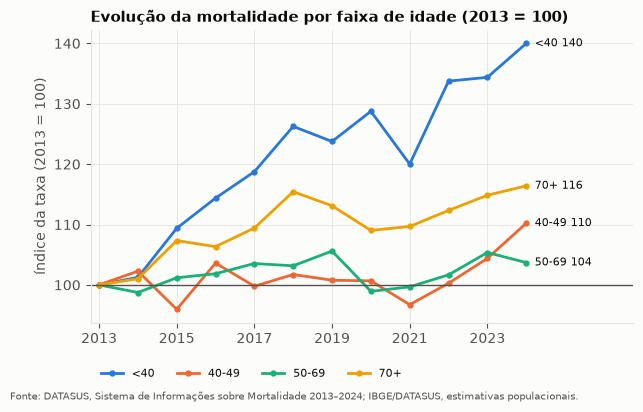

In [6]:
faixas = mort.taxa_por_grupo_etario(sim, pop, por=None)
base.salvar_tabela(faixas, "11_taxa_por_faixa_etaria_brasil")
tabela = faixas.pivot(index="ano", columns="grupo", values="taxa")[c.FAIXAS_ROTULOS]
display(tabela)
base_2013 = faixas[faixas.ano == 2013].set_index("grupo").taxa
indice = faixas.assign(indice=faixas.taxa / faixas.grupo.map(base_2013) * 100)
fig, ax = g.linhas(indice, "ano", "indice", "grupo", "Evolução da mortalidade por faixa de idade (2013 = 100)",
                   "índice da taxa (2013 = 100)", fmt="{:.0f}", ordem=c.FAIXAS_ROTULOS)
ax.axhline(100, color=g.TEXTO_2, lw=1)
g.salvar(fig, "11_indice_mortalidade_faixa_etaria", FONTE_SIM)
plt.show()

O grupo que mais cresceu foi o das mulheres com menos de 40 anos: a taxa passou de 1,6 para 2,2 óbitos por 100 mil, um aumento de 40%. As mulheres com 70 anos ou mais vêm em seguida, com 16%. As de 40 a 49 anos cresceram 10%, quase tudo nos últimos dois anos, e as de 50 a 69 anos, que são o alvo do rastreamento mamográfico, foram as que menos mudaram, 4%. É um resultado coerente com o caderno 04: as mulheres fora da faixa do rastreamento são as que chegam com doença mais avançada e as que concentram o aumento da mortalidade.

## Antes e depois dos 50 anos, por região

Por fim, juntamos idade e região, separando as mulheres em dois grupos: menos de 50 anos e 50 anos ou mais. Os dois gráficos têm escalas diferentes, já que a taxa das mais velhas é cerca de dez vezes maior. Leia cada um separadamente, olhando para a inclinação das linhas.

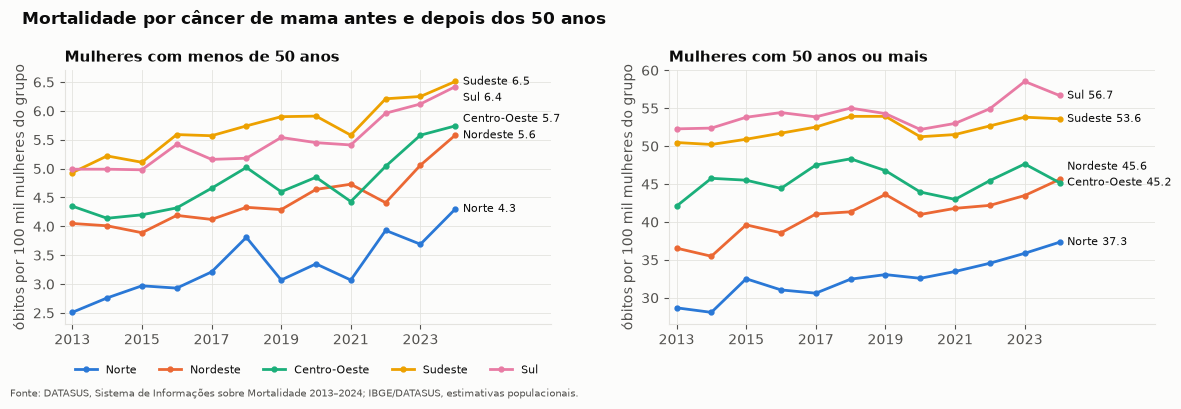

grupo,50 anos ou mais,Menos de 50 anos
regiao,,
Norte,30.2,71.3
Nordeste,24.8,37.8
Centro-Oeste,7.3,32.0
Sudeste,6.2,32.0
Sul,8.4,28.7


In [7]:
g50 = mort.taxa_por_grupo_etario(sim, pop, mort.GRUPOS_50, por="regiao")
base.salvar_tabela(g50, "11_taxa_menos_e_mais_50_regiao")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, grupo in zip(axes, ["Menos de 50 anos", "50 anos ou mais"]):
    g.linhas(g50[g50.grupo == grupo], "ano", "taxa", "regiao", f"Mulheres com {grupo.lower()}",
             "óbitos por 100 mil mulheres do grupo", ordem=c.REGIOES, ax=ax, legenda=(grupo == "Menos de 50 anos"))
fig.suptitle("Mortalidade por câncer de mama antes e depois dos 50 anos", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
g.salvar(fig, "11_mortalidade_menos_mais_50_regiao", FONTE_SIM)
plt.show()
v50 = mort.variacao(g50, "taxa", ["grupo", "regiao"], 2013, 2024)
base.salvar_tabela(v50, "11_variacao_menos_mais_50_regiao")
v50.pivot(index="regiao", columns="grupo", values="variacao_pct").reindex(c.REGIOES)

Entre as mulheres com menos de 50 anos, a mortalidade subiu em todas as regiões, e o Norte teve o maior aumento: de 2,5 para 4,3 óbitos por 100 mil, ou 71%. No Nordeste o aumento foi de 38%, no Centro-Oeste de 32%, no Sudeste de 32% e no Sul de 29%. Entre as mulheres com 50 anos ou mais, o aumento foi menor e concentrado de novo no Norte (30%) e no Nordeste (25%).

Há ainda um dado simples e forte: no Norte, 32% das mulheres que morrem de câncer de mama têm menos de 50 anos. No Sul, são 19%.

In [8]:
jovens = (sim.idade < 50).groupby(sim.regiao_res).mean().mul(100).round(1).reindex(c.REGIOES)
base.salvar_tabela(jovens.rename("pct_obitos_menos_50").to_frame(), "11_pct_obitos_menos_50_regiao", index=True)
jovens.rename("% dos óbitos em mulheres com menos de 50 anos").to_frame()

,% dos óbitos em mulheres com menos de 50 anos
regiao_res,
Norte,31.8
Nordeste,25.1
Centro-Oeste,25.7
Sudeste,21.1
Sul,19.4


## O que levar para o TCC

O número de óbitos por câncer de mama cresceu 47% entre 2013 e 2024, mas a maior parte desse aumento vem do crescimento e do envelhecimento da população: a mortalidade padronizada subiu 8%. O aumento real do risco se concentra no Norte (29%) e no Nordeste (19%) e nas mulheres com menos de 50 anos, sobretudo abaixo dos 40. Esses são os mesmos grupos que chegam com doença mais avançada e que esperam mais pelo tratamento, o que liga a mortalidade ao problema de acesso que o projeto discute. Ao citar números absolutos, é importante acompanhá-los da taxa padronizada, para não atribuir ao risco um aumento que é demográfico.